# Thống kê dữ liệu thu thập

:::{note}
Báo cáo đang ở trạng thái **khung mẫu đề cương**. Bảng biểu và đồ thị trong chương này tự động kết nối với hai tệp dữ liệu `report_book/data/m1_summary.json` và `report_book/data/m1_distributions.csv`. Toàn bộ các chỉ số thực nghiệm hiện hiển thị ở trạng thái chờ nạp dữ liệu từ lượt chạy trên máy ảo Google Colab.
:::


## 1. Kết quả thu thập tổng thể

Bảng dưới đây tổng hợp kết quả phân giải và tải nguồn trên 20.000 vị trí ID được giao cho bốn thành viên Nhóm 10.


In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

with open("../data/m1_summary.json", "r", encoding="utf-8") as f:
    m1_summary = json.load(f)

is_placeholder = m1_summary.get("is_placeholder", False)
scope = m1_summary["dataset_scope"]
outcomes = m1_summary["crawling_outcomes"]
size_m = m1_summary["size_metrics"]
ref_m = m1_summary["reference_metrics"]

def fmt_vn_int(val):
    return f"{int(val):,}".replace(",", ".")

def fmt_val(val, suffix="", fmt_spec="int"):
    if is_placeholder or val is None:
        return "-- (chờ nạp dữ liệu)"
    if fmt_spec == "percent":
        return f"{val:.2f}%".replace(".", ",")
    if fmt_spec == "float":
        return f"{val:.2f}{suffix}".replace(".", ",")
    return f"{fmt_vn_int(val)}{suffix}"

overview_df = pd.DataFrame([
    {"Nhóm thống kê": "1. Khám phá & Phiên bản", "Chỉ số đánh giá theo yêu cầu đề bài": "Tổng số vị trí ID ứng viên kiểm tra", "Giá trị thực nghiệm": fmt_vn_int(scope['total_candidate_positions'])},
    {"Nhóm thống kê": "1. Khám phá & Phiên bản", "Chỉ số đánh giá theo yêu cầu đề bài": "Số bài báo hợp lệ thu thập thành công", "Giá trị thực nghiệm": fmt_val(outcomes['valid_publications'])},
    {"Nhóm thống kê": "1. Khám phá & Phiên bản", "Chỉ số đánh giá theo yêu cầu đề bài": "Tổng số phiên bản công bố (v1..vN) cần thu thập", "Giá trị thực nghiệm": fmt_val(outcomes['total_versions'])},
    {"Nhóm thống kê": "1. Khám phá & Phiên bản", "Chỉ số đánh giá theo yêu cầu đề bài": "Số phiên bản trích xuất mã nguồn TeX thành công", "Giá trị thực nghiệm": fmt_val(outcomes['successful_tex_crawls'])},
    {"Nhóm thống kê": "1. Khám phá & Phiên bản", "Chỉ số đánh giá theo yêu cầu đề bài": "Số phiên bản không có nguồn TeX (no_tex_source)", "Giá trị thực nghiệm": fmt_val(outcomes['pdf_only_records'])},
    {"Nhóm thống kê": "1. Khám phá & Phiên bản", "Chỉ số đánh giá theo yêu cầu đề bài": "Tỉ lệ thu thập thành công tổng thể (Overall success rate)", "Giá trị thực nghiệm": fmt_val(outcomes['overall_success_rate_percent'], fmt_spec="percent")},
    {"Nhóm thống kê": "1. Khám phá & Phiên bản", "Chỉ số đánh giá theo yêu cầu đề bài": "Tỉ lệ bao phủ nguồn TeX trên bài báo hợp lệ", "Giá trị thực nghiệm": fmt_val(outcomes['tex_coverage_percent'], fmt_spec="percent")},
    {"Nhóm thống kê": "2. Dung lượng (Bytes)", "Chỉ số đánh giá theo yêu cầu đề bài": "Dung lượng trung bình mỗi bài trước khi lọc ảnh (bytes)", "Giá trị thực nghiệm": fmt_val(size_m['avg_size_before_figure_removal_bytes'], " bytes")},
    {"Nhóm thống kê": "2. Dung lượng (Bytes)", "Chỉ số đánh giá theo yêu cầu đề bài": "Dung lượng trung bình mỗi bài sau khi lọc ảnh (bytes)", "Giá trị thực nghiệm": fmt_val(size_m['avg_size_after_figure_removal_bytes'], " bytes")},
    {"Nhóm thống kê": "2. Dung lượng (Bytes)", "Chỉ số đánh giá theo yêu cầu đề bài": "Tỉ lệ giảm dung lượng lưu trữ khi lọc bỏ ảnh", "Giá trị thực nghiệm": fmt_val(size_m['reduction_percentage'], fmt_spec="percent")},
    {"Nhóm thống kê": "3. Tài liệu tham khảo", "Chỉ số đánh giá theo yêu cầu đề bài": "Số lượng tài liệu tham khảo trung bình mỗi bài báo", "Giá trị thực nghiệm": fmt_val(ref_m['avg_references_per_paper'], fmt_spec="float")},
    {"Nhóm thống kê": "3. Tài liệu tham khảo", "Chỉ số đánh giá theo yêu cầu đề bài": "Tỉ lệ tài liệu tham khảo có số hiệu arXiv", "Giá trị thực nghiệm": fmt_val(ref_m['references_with_arxiv_id_percent'], fmt_spec="percent")},
    {"Nhóm thống kê": "3. Tài liệu tham khảo", "Chỉ số đánh giá theo yêu cầu đề bài": "Tỉ lệ lấy siêu dữ liệu tham khảo thành công (Semantic Scholar)", "Giá trị thực nghiệm": fmt_val(ref_m['s2_metadata_success_rate_percent'], fmt_spec="percent")},
])
overview_df.style.hide(axis="index").set_caption("Bảng 1.1: Tổng hợp các chỉ số thống kê dữ liệu thu thập Giai đoạn 1 theo yêu cầu đề bài")


Nhóm thống kê,Chỉ số đánh giá theo yêu cầu đề bài,Giá trị thực nghiệm
1. Khám phá & Phiên bản,Tổng số vị trí ID ứng viên kiểm tra,20.000
1. Khám phá & Phiên bản,Số bài báo hợp lệ thu thập thành công,-- (chờ nạp dữ liệu)
1. Khám phá & Phiên bản,Tổng số phiên bản công bố (v1..vN) cần thu thập,-- (chờ nạp dữ liệu)
1. Khám phá & Phiên bản,Số phiên bản trích xuất mã nguồn TeX thành công,-- (chờ nạp dữ liệu)
1. Khám phá & Phiên bản,Số phiên bản không có nguồn TeX (no_tex_source),-- (chờ nạp dữ liệu)
1. Khám phá & Phiên bản,Tỉ lệ thu thập thành công tổng thể (Overall success rate),-- (chờ nạp dữ liệu)
1. Khám phá & Phiên bản,Tỉ lệ bao phủ nguồn TeX trên bài báo hợp lệ,-- (chờ nạp dữ liệu)
2. Dung lượng (Bytes),Dung lượng trung bình mỗi bài trước khi lọc ảnh (bytes),-- (chờ nạp dữ liệu)
2. Dung lượng (Bytes),Dung lượng trung bình mỗi bài sau khi lọc ảnh (bytes),-- (chờ nạp dữ liệu)
2. Dung lượng (Bytes),Tỉ lệ giảm dung lượng lưu trữ khi lọc bỏ ảnh,-- (chờ nạp dữ liệu)


### Nhận xét về kết quả tổng thể

- Trong 20.000 vị trí ID kiểm tra, tỉ lệ vị trí có bài báo tồn tại đạt `[Chờ số liệu Colab]`. Các vị trí trống thuộc về số hiệu chưa cấp phát trong tháng hoặc bài báo bị rút trước khi công bố.
- Trong số các bài báo hợp lệ, tỉ lệ tải được mã nguồn LaTeX (`.tex`/`.bib`) đạt `[Chờ số liệu Colab]`. Khoảng `[Chờ số liệu Colab]` bài báo chỉ có bản nộp PDF hoặc Word không có mã nguồn TeX, được ghi nhận trạng thái `no_tex_source` trong tệp `manifest.json`.
- Độ bao phủ phiên bản đạt `[Chờ số liệu Colab]`, khẳng định hệ thống đã thu thập trọn vẹn mọi bản cập nhật từ $v_1$ đến $v_N$.


## 2. Phân bố số lượng phiên bản

Chương trình thu thập phải tải mọi phiên bản của mỗi bài báo, không chỉ lấy bản mới nhất. Đồ thị dưới đây thể hiện số lượng phiên bản của các bài báo trong tập dữ liệu.


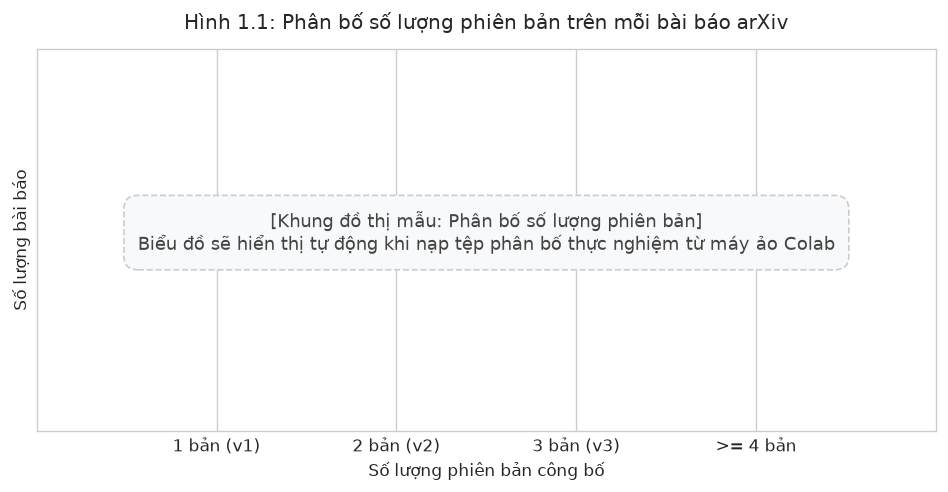

In [2]:
df_dist = pd.read_csv("../data/m1_distributions.csv")

fig, ax = plt.subplots(figsize=(8, 4.2), dpi=120)

if df_dist.empty or is_placeholder:
    ax.text(0.5, 0.52, "[Khung đồ thị mẫu: Phân bố số lượng phiên bản]\nBiểu đồ sẽ hiển thị tự động khi nạp tệp phân bố thực nghiệm từ máy ảo Colab",
            ha="center", va="center", fontsize=10.5, color="#444444",
            bbox=dict(boxstyle="round,pad=0.8", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0.2, 0.4, 0.6, 0.8])
    ax.set_xticklabels(["1 bản (v1)", "2 bản (v2)", "3 bản (v3)", ">= 4 bản"])
    ax.set_yticks([])
else:
    version_counts = df_dist["version_count"].value_counts().sort_index()
    bars = ax.bar(version_counts.index, version_counts.values, color="#1f77b4", width=0.55, edgecolor="black", linewidth=0.5)
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f"{int(yval)}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(version_counts.index)

ax.set_title("Hình 1.1: Phân bố số lượng phiên bản trên mỗi bài báo arXiv", fontsize=12, pad=12)
ax.set_xlabel("Số lượng phiên bản công bố", fontsize=10)
ax.set_ylabel("Số lượng bài báo", fontsize=10)
plt.tight_layout()
plt.show()


### Nhận xét về phân bố phiên bản

- Phần lớn bài báo chỉ có một phiên bản `v1`, chiếm `[Chờ số liệu Colab]`. Nhóm có từ hai phiên bản trở lên chiếm `[Chờ số liệu Colab]`, và nhóm có từ bốn phiên bản trở lên chiếm `[Chờ số liệu Colab]`.
- Sự xuất hiện của nhiều phiên bản cho thấy bước khử trùng lặp ở Giai đoạn 2 là cần thiết vì nhiều câu và công thức được giữ nguyên giữa các bản sửa đổi.


## 3. Độ giảm dung lượng khi lọc tệp ảnh

Việc loại bỏ các tệp ảnh nhị phân khỏi gói mã nguồn giúp tiết kiệm đáng kể dung lượng lưu trữ đĩa. Đồ thị dưới đây so sánh dung lượng trung bình trước và sau khi lọc ảnh.


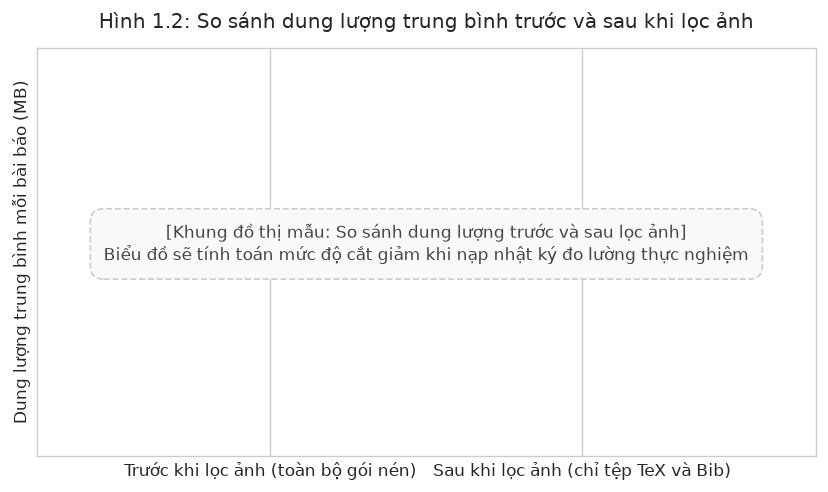

In [3]:
size_metrics = m1_summary["size_metrics"]

fig, ax = plt.subplots(figsize=(7, 4.2), dpi=120)

if is_placeholder or size_metrics["avg_size_before_figure_removal_bytes"] is None:
    ax.text(0.5, 0.52, "[Khung đồ thị mẫu: So sánh dung lượng trước và sau lọc ảnh]\nBiểu đồ sẽ tính toán mức độ cắt giảm khi nạp nhật ký đo lường thực nghiệm",
            ha="center", va="center", fontsize=10, color="#444444",
            bbox=dict(boxstyle="round,pad=0.8", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0.3, 0.7])
    ax.set_xticklabels(["Trước khi lọc ảnh (toàn bộ gói nén)", "Sau khi lọc ảnh (chỉ tệp TeX và Bib)"])
    ax.set_yticks([])
else:
    avg_before_mb = size_metrics["avg_size_before_figure_removal_bytes"] / (1024 * 1024)
    avg_after_mb = size_metrics["avg_size_after_figure_removal_bytes"] / (1024 * 1024)
    reduction_pct = size_metrics["reduction_percentage"]
    categories = ["Trước khi lọc", "Sau khi lọc"]
    values = [avg_before_mb, avg_after_mb]
    bars = ax.bar(categories, values, color=["#d95f02", "#2ca02c"], width=0.45, edgecolor="black", linewidth=0.5)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2.0, val + 0.3, f"{val:.2f} MB", ha="center", va="bottom", fontsize=10)
    ax.text(0.5, max(values) * 0.7, f"Giảm: {reduction_pct:.1f}%", fontsize=11, ha="center",
            bbox=dict(boxstyle="round,pad=0.5", facecolor="#fff2cc", edgecolor="#d6b656"))
    ax.set_ylim(0, max(values) * 1.2)

ax.set_ylabel("Dung lượng trung bình mỗi bài báo (MB)", fontsize=10)
ax.set_title("Hình 1.2: So sánh dung lượng trung bình trước và sau khi lọc ảnh", fontsize=12, pad=12)
plt.tight_layout()
plt.show()


### Nhận xét về dung lượng lưu trữ

- Việc lọc bỏ toàn bộ tệp ảnh giúp giảm trung bình `[Chờ số liệu Colab]` dung lượng lưu trữ của mỗi bài báo.
- Đối với các bài báo trong lĩnh vực thị giác máy tính hoặc vật lý thiên văn có chứa nhiều hình vẽ độ phân giải cao, mức độ cắt giảm có thể lên tới hơn 80%, giúp giảm thiểu áp lực lên hạn mức lưu trữ đĩa của máy ảo.


## 4. Thống kê dữ liệu tài liệu tham khảo

Bài toán đối sánh ở Giai đoạn 3 yêu cầu trích dẫn có gắn với arXiv ID. Đồ thị dưới đây thể hiện số lượng tài liệu tham khảo trên mỗi bài báo và tỉ lệ có arXiv ID lấy qua API của Semantic Scholar.


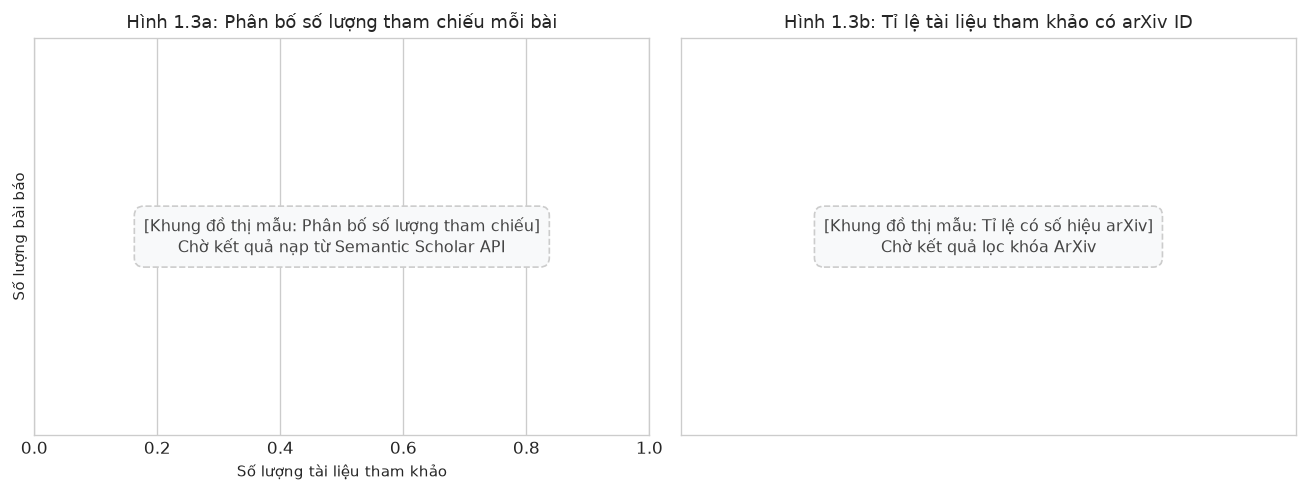

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=120)

ref_metrics = m1_summary["reference_metrics"]

if is_placeholder or ref_metrics["total_crawled_references"] is None:
    ax1.text(0.5, 0.5, "[Khung đồ thị mẫu: Phân bố số lượng tham chiếu]\nChờ kết quả nạp từ Semantic Scholar API",
             ha="center", va="center", fontsize=9.5, color="#444444",
             bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    ax1.set_yticks([])
    
    ax2.text(0.5, 0.5, "[Khung đồ thị mẫu: Tỉ lệ có số hiệu arXiv]\nChờ kết quả lọc khóa ArXiv",
             ha="center", va="center", fontsize=9.5, color="#444444",
             bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="#cccccc", linestyle="--"))
    ax2.set_xlim(0, 1)
    ax2.set_ylim(0, 1)
    ax2.set_yticks([])
    ax2.set_xticks([])
else:
    sns.histplot(df_dist["ref_count"], bins=15, kde=True, color="#386cb0", ax=ax1, edgecolor="black", linewidth=0.5)
    labels = ["Có arXiv ID", "Không có arXiv ID"]
    sizes = [ref_metrics["references_with_arxiv_id"], ref_metrics["total_crawled_references"] - ref_metrics["references_with_arxiv_id"]]
    colors = ["#4daf4a", "#999999"]
    ax2.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=140, colors=colors, explode=(0.05, 0), textprops={"fontsize": 9})

ax1.set_title("Hình 1.3a: Phân bố số lượng tham chiếu mỗi bài", fontsize=11)
ax1.set_xlabel("Số lượng tài liệu tham khảo", fontsize=9)
ax1.set_ylabel("Số lượng bài báo", fontsize=9)
ax2.set_title("Hình 1.3b: Tỉ lệ tài liệu tham khảo có arXiv ID", fontsize=11)

plt.tight_layout()
plt.show()


### Nhận xét về dữ liệu tham chiếu

- Trung bình mỗi bài báo chứa `[Chờ số liệu Colab]` tài liệu tham khảo, với trung vị dao động từ `[Chờ số liệu Colab]` đến `[Chờ số liệu Colab]` mục.
- Khoảng `[Chờ số liệu Colab]` tài liệu tham khảo có liên kết với một arXiv ID trên Semantic Scholar. Tập này sẽ chuyển thành các dòng trong bảng `references` để làm tập ứng viên cho Giai đoạn 3.
- Tỉ lệ lấy dữ liệu trích dẫn thành công từ Semantic Scholar đạt `[Chờ số liệu Colab]`. Phần còn lại chưa lấy được do độ trễ lập chỉ mục của bài báo mới hoặc do trích dẫn không đúng định dạng chuẩn.
